# Encoding categorical variables.
### Objectives.
- Explain why categorical variables must be encoded for ML models.
- Choose between label encoding and one-hot encoding correctly.
- Handle high-cardinality categorical features with target encoding.

### What is encoding?

### Why encode?
- ML models work with numbers.
e.g A column that contains red, green and blue must be converted.
red = 1, blue = 2 and green = 3.

- Problem: The model thinks green>blue>red,  this is a false relationship.

### Core Principle
- Encoding should not introduce meaning that does not exist.
### Method 1: Label Encoding.
Assingns each cat a number:
Only use when categories have a natural order, small -> 0, medium->1, arge ->2.

eg Rating (1-5 stars), education level.
When not use:
- Gender
- City
- Color

### Method 2: One Hot Encoding
For Example:
1 column - color(red, blue,green).
|color|
| ---|
|red|
|blue|
|green|
|red|
 
|color_red| color_blue| color_green |
|---|---|---|
|1|0|0
|0|1|0
|0|0|1
|1|0|0


In [1]:
import pandas as pd
# Label encoding and categorical encoding.

df_sample = pd.DataFrame({ 
    'color': ['red', 'blue', 'green', 'red', 'blue'],
    'size': ['small', 'medium', 'large', 'medium','small']
})



In [4]:
# since size is ordinal ( has a natural order)

size_map = {'small':0, 'medium':1,'large':2}
df_sample['size_encoded'] = df_sample['size'].map(size_map)

print(df_sample[['size', 'size_encoded']].head())
      

     size  size_encoded
0   small             0
1  medium             1
2   large             2
3  medium             1
4   small             0


In [5]:
#  One hot encoding
# Using Pandas

df_encoded =pd.get_dummies(df_sample, columns=['color'], drop_first=True)
print(df_encoded)

     size  size_encoded  color_green  color_red
0   small             0        False       True
1  medium             1        False      False
2   large             2         True      False
3  medium             1        False       True
4   small             0        False      False


In [9]:
# Using sklearn (preferred for pipelines)
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop='first', sparse_output=False)
color_encoded = ohe.fit_transform(df_sample[['color']])
feature_names = ohe.get_feature_names_out(['color'])
print(pd.DataFrame(color_encoded, columns=feature_names))

   color_green  color_red
0          0.0        1.0
1          0.0        0.0
2          1.0        0.0
3          0.0        1.0
4          0.0        0.0


In [10]:
color_encoded

array([[0., 1.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [0., 0.]])

### Note: Watch out for the dummy variable trap.

If you have three categories (red, blue, green) and create 3 binary columns, the 3rd column is 
always predicatble from the other two.
This is called multi-colinearity and can destabilize some models
Always use drop ="first" or drop_first = True or drop one category'

## High cardinality problem.
- What if we have 1000 unique categories?
EXAMPLE:
- UserIDs
- Product IDs
- Zip codes.

### One-hot problem
- creates a huge matrix.
- slow training.
- can overfit.

### Fix: 
- Target encoding(/mean encoding) replaces each category with the mean of the target.




Original data:
|neigborhood|price|
|---|---|
|downtown|500k|
|downtown|600k|
|downtown|700k|
|uptown|1000k|
|uptown|1200k|
|suburbs|200k|
|suburbs|300k|
 
 One hot encoding:

|neighborhood downtown|neighborhood uptown|neighborhood suburbs|price|
|---|---|---|---|
|1|0|0|500k|
 
 Target Encoding:

|neigborhood|price|
|---|---|
|600k|500k|
|600k|600k|
|600k|700k|
|1100k|1000k| ...

In [14]:


def target_encode(train_df, val_df,col,target, smoothing=10):
    # smooth target enconding to avoid overfitting.
    global_mean = train_df[target].mean()
    agg = train_df.groupby(col)[target].agg(['mean', 'count']) # grouping all rows with categories

    # smooth: Blend category mean with global mean but based on count
    smoother = agg['count'] + smoothing
    encoded =  smoother * agg['mean'] + (1-smoother) * global_mean

    # Map to validation set
    val_encoded = val_df[col].map(encoded).fillna(global_mean)
    return val_encoded


In [17]:
df_houses = pd.DataFrame({
    'neighborhood': ['downtown', 'downtown', 'downtown', 'uptown', 'uptown', 'suburbs', 'suburbs'],
    'target': [500, 600, 700, 1000, 1200,200, 300]
})


In [19]:
houses_means = df_houses.groupby('neighborhood')['target'].mean()
df_houses['neighborhood_encoded'] = df_houses['neighborhood'].map(houses_means)

print(df_houses)

  neighborhood  target  neighborhood_encoded
0     downtown     500                 600.0
1     downtown     600                 600.0
2     downtown     700                 600.0
3       uptown    1000                1100.0
4       uptown    1200                1100.0
5      suburbs     200                 250.0
6      suburbs     300                 250.0


In [ ]:
target_encode(df_houses, 'neighborhood', 'target')

TypeError: target_encode() missing 1 required positional argument: 'target'

## Feature Scaling
### Objectives.
1. Explain why scaling is necessary for distance-based and gradient-based models.
2. Choose between Standard Scaler and MinMaxScaler correctly.
3. Avoid the data leakage mistakd with scalers.


### Core principle
Features with large numbers dominate distance and optimization.

### Algorithims that need scaling.
- KNN, K-means, Support Vector Machines(SVM).
- Logistic regression, Linear regression - gradient-based optimization (converge faster)
- Neural networks.

### Algorithims affected by scaling (scaling is optional):
- Decision trees.
- Random forests.
- XGBoost.




## 1. Standard Scaler
- Uses the distance from the mean

Formula:
``` Z = (x - mean)/sd. ```
Meaning
Our data is going to transformed such that:
    mean = 0
    standard deviation = 1

``` python
    ...
    from sklearn.preprocessing import StandardScaler

    scaler = StandardScaler()

    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    ...
```
## Best for:
- Most ML problems.
- Logistic regreesion.
- SVM.
- PCA.

## Limitation
- Sensitive to outliers.
-  


## 2. MinMaxScaler

Formula:
   ``` z = (x -xmim)/ (xmax -xmin) ```

Output range:
   ``` 0 and 1 ```

### How to implement the MinMaxScaler:
``` python
    ...
    from sklearn.preprocessing import MinMaxScaler

    scaler = MinMaxScaler()

    scaler.fit(X_train) # Assuming you have already split your data
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    ...
```
Best for:
- Neural networks.
- Image data.
- Features needing bounding ranges.

Limitation:
- Very sensitive to outliers.
One huge value compreses everything else.


## 3. Robust Scaler.
Formula:
   ``` Z = (x - median)/ IQR ```
   where: IQR = inter-quartile-range
   ```IQR = Q3 - Q1 ```

why useful:
- Uses the median
- Uses IQR
More resistant to outliers

Best for:
- Financial data.
- Messy real-world data.
- Heavy-tailed distribution.



In [1]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import numpy as np

# sample data
X = np.array([
 [25, 50000, 1.75],
 [30, 80000, 1.65],
 [45, 35000, 1.90],
 [22, 120000, 1.70]

])

# Standard scaler - most situations, gausian - like data.
ss = StandardScaler()
X_std = ss.fit_transform(X)

print(X_std.round(2))
print(f'Mean: {X_std.mean(axis=0).round(2)} | std: {X_std.std(axis=0).round(2)}')



[[-0.62 -0.65  0.  ]
 [-0.06  0.27 -1.07]
 [ 1.64 -1.12  1.6 ]
 [-0.96  1.5  -0.53]]
Mean: [ 0.  0. -0.] | std: [1. 1. 1.]


In [5]:
# MinMax normalization ( range 0 and 1)
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler()
X_norm = mm.fit_transform(X)
print(X_norm.round(2))

[[0.13 0.18 0.4 ]
 [0.35 0.53 0.  ]
 [1.   0.   1.  ]
 [0.   1.   0.2 ]]


In [4]:
# Robust Scaler (uses median and IQR)
from sklearn.preprocessing import RobustScaler
rs = RobustScaler()
X_robust = rs.fit_transform(X)
 
print(X_robust.round(2))

[[-0.26 -0.34  0.25]
 [ 0.26  0.34 -0.75]
 [ 1.84 -0.69  1.75]
 [-0.58  1.26 -0.25]]


## Feature Selection
- The process of choosing the most useful input variables for a ML model. 
### Objectives

1. Explain why too many features can hurt a model.
2. Implement 3 feature selection methods in python.
3. Know when to apply each method.



### Why select features?
- Fewer features = faster training, simple model, less overfitting.
- Irrelevant features add noise and can confuse the model.
- Highly correlated features are redundant - they add no new info.





## Feature Selection Methods

### Method 1: Correlation-based selection.
- Remove highly correlated features because they are redundant.

Best for: 
- Quick preprocessing.
- Removing duplicate information.
- Numerical features.


In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer


In [13]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, data.target)

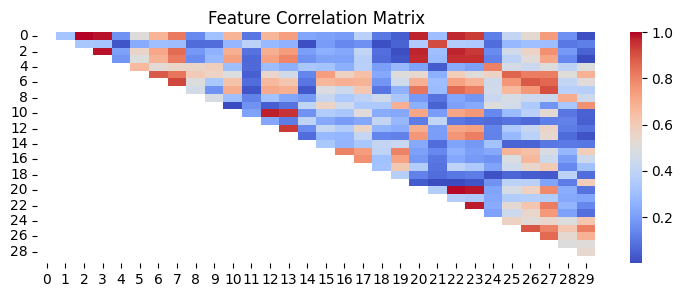

In [19]:
# correlation heatmap
plt.figure(figsize=(9,3))
corr = df.corr().abs()

sns.heatmap(upper, cmap='coolwarm', vmax =1 )
plt.title('Feature Correlation Matrix')
plt.show()

In [23]:
# Identifying pairs with high correlation.
import numpy as np
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)

)
highly_correlated = [col for col in upper.columns
                     if any(upper[col] > 0.9)]


In [22]:
print(upper.columns)
highly_correlated

RangeIndex(start=0, stop=30, step=1)


[2, 3, 7, 12, 13, 20, 21, 22, 23, 27]

In [25]:
# Statistical test to select features
# Select the top features that have the strongest relationship with the target
# f_classid -> classification tasks, linear relationships
# mutual info_classif -> works well for non-linear relationships.

data2 = load_breast_cancer()

X, y =data2.data, data2.target

In [26]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=10)
X_selected = selector.fit_transform(X, y)

X_selected.shape

(569, 10)

In [27]:
X.shape

(569, 30)

In [31]:
selected_names = [data.feature_names[i]
                  for i in selector.get_support(indices = True)
                  ]
for name in selected_names:
    print(name)

mean radius
mean perimeter
mean area
mean concavity
mean concave points
worst radius
worst perimeter
worst area
worst concavity
worst concave points


In [30]:
data.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [33]:
# Recursive feature elimination
# 1. Train the model
# 2. Remove the least important feature.
# 3. Repeat until only the best features remain.
# Best for: tree_based models, high accuracy.
# This's computationaly expensive and slower than the other models.

from sklearn.feature_selection import RFE, RFECV
from sklearn.ensemble import RandomForestClassifier

data3 = load_breast_cancer()
X, y = data3.data, data3.target

rfecv = RFECV(
    estimator = RandomForestClassifier(random_state=42),
    step=1,
    cv=5,
    scoring='accuracy',
    n_jobs=1

 )
rfecv.fit(X, y)

,estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance either through a ``coef_``attribute or through a ``feature_importances_`` attribute.,RandomForestC...ndom_state=42)
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.Note that the last iteration may remove fewer than ``step`` features inorder to reach ``min_features_to_select``.",1
,"min_features_to_select min_features_to_select: int, default=1The minimum number of features to be selected. This number of featureswill always be scored, even if the difference between the originalfeature count and ``min_features_to_select`` isn't divisible by``step``... versionadded:: 0.20",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If theestimator is not a classifier or if ``y`` is neither binary nor multiclass,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value of None changed from 3-fold to 5-fold.",5
,"scoring scoring: str or callable, default=NoneScoring method to evaluate the :class:`RFE` selectors' performance. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion ` is used.",'accuracy'
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"n_jobs n_jobs: int or None, default=NoneNumber of cores to run in parallel while fitting across folds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionadded:: 0.18",1
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance.For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case of:class:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None


In [35]:
best_features = [data3.feature_names[i] 
                 for i in rfecv.get_support(indices=True)]
len(best_features)

16